# 03 · Optimizer sanity check

Before the optimizers touch the football data they have to prove themselves where a run costs seconds:

1. **Toy problem** (T3.6, T4.1, T4.2): minimise the number of selected features. The optimum is known (a single 1), so a bug or a bad setting shows immediately.
2. **Breast Cancer Wisconsin** (T3.7, T4.4; the setting of the course's Practicals 4, 5 and 7): a real feature-selection problem with 30 features, where each optimizer should match or beat random search.

All optimizers share one interface, `run(fitness, D, init_pop, budget, rng)`, the same starting population per seed and the same budget.
The same properties are also checked by the unit tests in `tests/test_optimizers.py`.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

from src import config
from src.optimizers import ALL_RUNNERS, init_population, run_rng
from src.plotting import METHOD_LABEL, METHOD_STYLE, ORANGE, method_kwargs, plt, save, set_style

set_style()
config.ensure_dirs()
threadpool_limits(1)      # the matrices here are tiny: one BLAS thread is far faster than sixteen competing ones
pd.set_option("display.width", 200)

ALGS = ["ga", "bpso", "bgwo", "random"]
LABEL = dict(METHOD_LABEL, bpso_w_dec="Binary PSO, w 0.9→0.4")
STYLE = dict(METHOD_STYLE, bpso_w_dec=dict(label=LABEL["bpso_w_dec"], color=ORANGE, linestyle=(0, (1, 1)), marker="x"))


def run_all(fitness, D, budget, seeds, algs, pop_size=config.POP_SIZE):
    """Run every algorithm on every seed and return {algorithm: [OptResult per seed]}."""
    return {alg: [ALL_RUNNERS[alg](fitness, D, init_population(s, pop_size, D), budget, run_rng(s)) for s in seeds]
            for alg in algs}


def convergence_plot(results, ax, every=1):
    for alg, runs in results.items():
        curves = np.array([r.history for r in runs])
        mean, sd = curves.mean(axis=0), curves.std(axis=0)
        calls = np.arange(1, curves.shape[1] + 1)
        kw = dict(STYLE[alg])
        ax.plot(calls, mean, markevery=max(len(calls) // 8, 1), **kw)
        ax.fill_between(calls, mean - sd, mean + sd, color=kw["color"], alpha=0.10, linewidth=0)
    ax.set_xlabel("Fitness evaluations")
    ax.legend()

## 1. Toy problem: minimise the number of 1s

`fitness(x) = number of selected features`, D = 45, population 20, budget 600: the same sizes as the football experiment.
The all-zero vector is not allowed (it is repaired to one random feature), so the best possible fitness is 1.

In [2]:
def count_ones(mask):
    return float(np.sum(mask))

TOY_SEEDS = range(10)
toy = run_all(count_ones, D=45, budget=config.BUDGET, seeds=TOY_SEEDS, algs=ALGS + ["bpso_w_dec"])

def toy_table(results):
    rows = {}
    for alg, runs in results.items():
        best = np.array([r.best_fitness for r in runs])
        reached = np.array([np.argmax(r.history == r.history[-1]) + 1 for r in runs])
        rows[LABEL[alg]] = {"best fitness per seed": " ".join(str(int(b)) for b in best),
                            "mean": best.mean(), "runs at optimum (of 10)": int((best == 1).sum()),
                            "mean calls to reach final value": reached.mean(),
                            "final diversity": np.mean([r.diversity[-1] for r in runs]) if runs[0].diversity else np.nan}
    return pd.DataFrame(rows).T

toy_table(toy)

,best fitness per seed,mean,runs at optimum (of 10),mean calls to reach final value,final diversity
GA,1 1 1 1 1 1 1 1 1 1,1.0,10,336.7,2.998421
Binary PSO,1 1 1 1 1 1 1 1 1 1,1.0,10,455.0,4.436316
Binary GWO,1 1 1 1 1 1 1 1 1 1,1.0,10,143.5,2.252105
Random search,14 11 11 12 14 11 13 13 11 13,12.3,0,287.5,NaN
"Binary PSO, w 0.9→0.4",7 7 5 8 8 7 7 8 7 7,7.1,0,321.6,20.635263


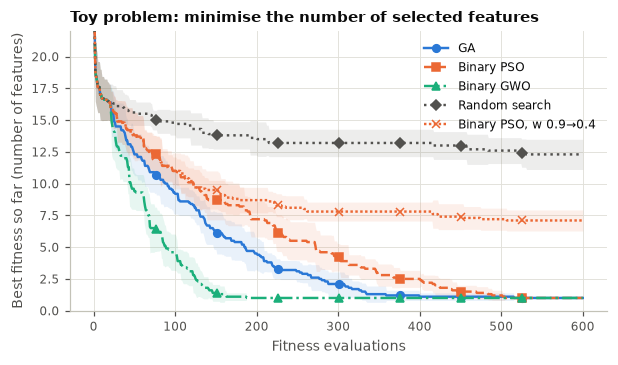

In [3]:
fig, ax = plt.subplots(figsize=(6.3, 3.3))
convergence_plot(toy, ax)
ax.set(ylabel="Best fitness so far (number of features)", title="Toy problem: minimise the number of selected features")
ax.set_ylim(0, 22)
save(fig, "fig03a_toy_convergence")
plt.show()

**Result.**

* The **GA** and **Binary GWO** reach the optimum (one feature) on all 10 seeds. They pass the toy test.
* **Random search** stops at 11 to 14 features: with 600 random draws of 45 fair coins, that is about as low as chance goes.
* **Binary PSO with the plan's starting-point setting** (inertia weight falling from 0.9 to 0.4) stalls at about 7 features and its swarm never contracts (final diversity about 20, where a random population has 22.5). It fails the toy test.

**Why the falling inertia weight fails in the binary version.**
In continuous PSO a small velocity means a particle has stopped moving, so lowering the inertia weight helps fine-tuning.
In binary PSO the velocity is turned into a probability by a sigmoid, and a velocity near 0 means "this bit is 1 with probability 0.5", which is a coin flip.
When a bit already agrees with the particle's best and the swarm's best, the two attraction terms are zero and the update is just `v = w·v`: any `w < 1` pulls the velocity back to 0 and the bit becomes random again.
The lower the weight, the more random the swarm, the opposite of what the schedule is meant to do.

**Decision (logged as D15).** The main experiment uses the original binary PSO of Kennedy and Eberhart (1997), which has no inertia damping (`w = 1`), with everything else as planned (c1 = c2 = 2, velocity clamp ±6, sigmoid transfer).
With `w = 1` the swarm reaches the optimum on all 10 seeds.
This was decided here, on the toy problem, before any football run.
The plan's schedule is kept as an ablation (`bpso_w_dec`) and reported separately.

## 2. Breast Cancer Wisconsin

569 tumours, 30 features, built into scikit-learn. The fitness has the same form as the football one:

$$f(\mathbf{x}) = 0.99\,(1 - \text{accuracy}_{\text{5-fold CV}}(\mathbf{x})) + 0.01\,\frac{|\mathbf{x}|}{30}$$

with a standardised logistic regression as the model. Budget: 300 calls, population 20, seeds 0 to 4.

In [4]:
X, y = load_breast_cancer(return_X_y=True)
D_BC = X.shape[1]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
ALPHA = 0.99
accuracy_cache = {}


def cv_accuracy(mask):
    key = np.asarray(mask, dtype=np.uint8).tobytes()
    if key not in accuracy_cache:
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        accuracy_cache[key] = cross_val_score(model, X[:, np.asarray(mask, dtype=bool)], y, cv=CV, scoring="accuracy").mean()
    return accuracy_cache[key]


def bc_fitness(mask):
    return ALPHA * (1 - cv_accuracy(mask)) + (1 - ALPHA) * np.sum(mask) / D_BC


all_features = np.ones(D_BC, dtype=np.uint8)
print(f"X: {X.shape}, positives: {y.mean():.1%}")
print(f"all 30 features: CV accuracy {cv_accuracy(all_features):.4f}, fitness {bc_fitness(all_features):.5f}")

X: (569, 30), positives: 62.7%
all 30 features: CV accuracy 0.9789, fitness 0.03087


### 2.1 GA against random search (T3.7)

In [5]:
BC_SEEDS, BC_BUDGET = range(5), 300
start = time.perf_counter()
bc = run_all(bc_fitness, D_BC, BC_BUDGET, BC_SEEDS, ["ga", "random"])
print(f"{time.perf_counter() - start:.0f} s")


def bc_rows(results):
    rows = []
    for alg, runs in results.items():
        for seed, r in zip(BC_SEEDS, runs):
            rows.append({"algorithm": alg, "seed": seed, "fitness": r.best_fitness,
                         "cv_accuracy": cv_accuracy(r.best_mask), "n_features": r.n_selected})
    return pd.DataFrame(rows)


ga_vs_random = bc_rows(bc).pivot(index="seed", columns="algorithm", values="fitness")[["ga", "random"]]
ga_vs_random["GA at or below random"] = ga_vs_random["ga"] <= ga_vs_random["random"]
ga_vs_random.round(5)

104 s


algorithm,ga,random,GA at or below random
seed,,,
0,0.02026,0.02280,True
1,0.01686,0.02066,True
2,0.01651,0.02347,True
3,0.01652,0.02340,True
4,0.01759,0.01926,True


In [6]:
assert ga_vs_random["GA at or below random"].all()
print("GA matches or beats random search on every seed")

GA matches or beats random search on every seed


### 2.2 All four optimizers (T4.4)

In [7]:
start = time.perf_counter()
bc.update(run_all(bc_fitness, D_BC, BC_BUDGET, BC_SEEDS, ["bpso", "bgwo", "bpso_w_dec"]))
bc = {alg: bc[alg] for alg in ALGS + ["bpso_w_dec"]}
print(f"{time.perf_counter() - start:.0f} s, {len(accuracy_cache)} distinct subsets evaluated in total")

runs = bc_rows(bc)
runs.to_csv(config.SANITY_DIR / "breast_cancer_runs.csv", index=False)
fit = runs.pivot(index="seed", columns="algorithm", values="fitness")[ALGS + ["bpso_w_dec"]]
fit.rename(columns=LABEL).round(5)

127 s, 6009 distinct subsets evaluated in total


algorithm,GA,Binary PSO,Binary GWO,Random search,"Binary PSO, w 0.9→0.4"
seed,,,,,
0,0.02026,0.01819,0.01826,0.02280,0.01786
1,0.01686,0.01784,0.01651,0.02066,0.01924
2,0.01651,0.01791,0.01477,0.02347,0.02198
3,0.01652,0.01651,0.01826,0.02340,0.01893
4,0.01759,0.01926,0.01817,0.01926,0.02207


In [8]:
summary = runs.groupby("algorithm").agg(
    fitness_mean=("fitness", "mean"), fitness_sd=("fitness", "std"),
    cv_accuracy=("cv_accuracy", "mean"), n_features=("n_features", "mean")).loc[ALGS + ["bpso_w_dec"]]
summary["seeds at or below random (of 5)"] = [int((fit[a] <= fit["random"]).sum()) for a in summary.index]
summary.index = [LABEL[a] for a in summary.index]
summary.to_csv(config.SANITY_DIR / "breast_cancer_summary.csv")
summary.round(5)

,fitness_mean,fitness_sd,cv_accuracy,n_features,seeds at or below random (of 5)
GA,0.01755,0.00158,0.98699,14.0,5
Binary PSO,0.01794,0.00098,0.98700,15.2,5
Binary GWO,0.01719,0.00155,0.98735,14.0,5
Random search,0.02192,0.00187,0.98278,14.6,5
"Binary PSO, w 0.9→0.4",0.02001,0.00190,0.98524,16.2,4


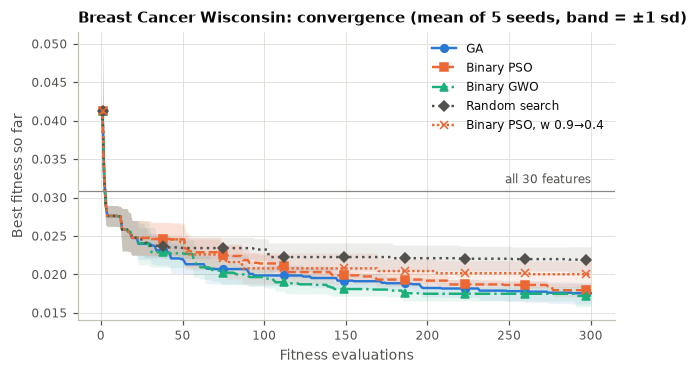

In [9]:
fig, ax = plt.subplots(figsize=(6.3, 3.4))
convergence_plot(bc, ax)
ax.set(ylabel="Best fitness so far", title="Breast Cancer Wisconsin: convergence (mean of 5 seeds, band = ±1 sd)")
ax.axhline(bc_fitness(all_features), color="#898781", linewidth=0.8)
ax.annotate("all 30 features", (BC_BUDGET, bc_fitness(all_features)), xytext=(0, 3), textcoords="offset points",
            ha="right", va="bottom", fontsize=8, color="#52514e")
save(fig, "fig03b_breast_cancer_convergence")
plt.show()

In [10]:
for alg in ["ga", "bpso", "bgwo"]:
    assert (fit[alg] <= fit["random"]).all(), alg
print("GA, Binary PSO (w = 1) and Binary GWO each match or beat random search on every seed")

GA, Binary PSO (w = 1) and Binary GWO each match or beat random search on every seed


## Verdict

* **Toy problem:** GA, Binary PSO (`w = 1`) and Binary GWO reach the known optimum on all 10 seeds; random search does not come close.
* **Breast Cancer Wisconsin:** all three metaheuristics match or beat random search on all 5 seeds, with fewer features and a cross-validated accuracy at least as high as with all 30 features.
* **Binary PSO setting:** the falling inertia weight from the plan's starting-point settings fails the toy test and is the weakest metaheuristic here too. It is replaced by `w = 1` for the main experiment and kept as an ablation.

The optimizers, the shared helpers and the plotting code work. The football runs can start.